In [1]:
# Cell 1: Import library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import os, random, time, copy, torch
from pathlib import Path

import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import models, transforms
from PIL import Image
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

In [2]:
# Cell 2: Load data & setups
# Set seeds
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed = 42

# Paths
AUDIT_DIR = Path("../reports/audit")
RAW_DATA_DIR = Path("../data/raw/data1a")
PROCESSED_DIR = Path("../data/processed")
MODELS_DIR = Path("../models")
MODELS_DIR.mkdir(parents=True, exist_ok = True)
FIGURES_DIR = Path("../reports/figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [3]:
# Cell 3: EXP-00 Metadata Baseline
print("--- EXP-00: Metadata-only Baseline ---")

# Load splits
df_train = pd.read_csv(PROCESSED_DIR / "train_split.csv")
df_val = pd.read_csv(PROCESSED_DIR / "val_split.csv")
df_test = pd.read_csv(PROCESSED_DIR / "test_split.csv")

# Features to use
features = ["width", "height", "aspect_ratio"]

# Train Decision Tree
dt = DecisionTreeClassifier(max_depth=3, random_state=42)
dt.fit(df_train[features], df_train["target"])

# Evaluate on Test
y_pred = dt.predict(df_test[features])
y_prob = dt.predict_proba(df_test[features])[:, 1]

accuracy = accuracy_score(df_test["target"], y_pred)
precision = precision_score(df_test["target"], y_pred)
recall = recall_score(df_test["target"], y_pred)
f1 = f1_score(df_test["target"], y_pred)
auc = roc_auc_score(df_test["target"], y_prob)

print(f"Test Accuracy: {accuracy:.4f}")
print(f"Test Precision: {precision:.4f}")
print(f"Test Recall: {recall:.4f}")
print(f"Test F1-Score: {f1:.4f}")
print(f"Test ROC-AUC: {auc:.4f}")

# Save to experiment log
exp_log = pd.DataFrame([{
    "experiment_id": "EXP-00",
    "model_name": "DecisionTree_Metadata",
    "learning_rate": np.nan,
    "batch_size": np.nan,
    "epochs": np.nan,
    "accuracy": accuracy,
    "precision": precision,
    "recall": recall,
    "f1_score": f1,
    "roc_auc": auc,
    "training_time": np.nan,
    "inference_time": np.nan
}])

# Save or append to experiment_log.csv
log_path = PROCESSED_DIR / "experiment_log.csv"
if log_path.exists():
    existing_log = pd.read_csv(log_path)
    exp_log = pd.concat([existing_log, exp_log], ignore_index=True)
exp_log.to_csv(log_path, index=False)
print(f"\nSaved EXP-00 to {log_path}")

--- EXP-00: Metadata-only Baseline ---
Test Accuracy: 0.8555
Test Precision: 0.7748
Test Recall: 1.0000
Test F1-Score: 0.8731
Test ROC-AUC: 0.8841

Saved EXP-00 to ..\data\processed\experiment_log.csv


In [4]:
# Cell 4: Setup DataLoaders
# 1. Transforms

train_transforms = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomCrop(224),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.05),
    transforms.RandomApply([transforms.GaussianBlur(kernel_size=3, sigma=(0.1, 2.0))], p=0.3),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_test_transforms = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# 2. Dataset Class
class CarDamageDataset(torch.utils.data.Dataset):
    def __init__(self, dataframe, root_dir, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.root_dir = root_dir
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_rel_path = self.df.loc[idx, "image_path"]
        img_path = self.root_dir / img_rel_path
        label = self.df.loc[idx, "target"]
        image = Image.open(img_path).convert("RGB")
        if self.transform:
            image = self.transform(image)
        return image, label

# 3. DataLoaders
BATCH_SIZE = 32
train_loader = DataLoader(CarDamageDataset(df_train, RAW_DATA_DIR, train_transforms), batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(CarDamageDataset(df_val, RAW_DATA_DIR, val_test_transforms), batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(CarDamageDataset(df_test, RAW_DATA_DIR, val_test_transforms), batch_size=BATCH_SIZE, shuffle=False, num_workers=0)


print("DataLoaders ready.")

DataLoaders ready.


In [5]:
# Cell 5: Trining Engine
def train_one_experiment(model, train_loader, val_loader, epochs, lr, experiment_name, device=device):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    # Track history
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val_loss = float('inf')
    best_model_wts = copy.deepcopy(model.state_dict())

    print(f"Starting {experiment_name} for {epochs} epochs...")
    start_time = time.time()

    for epoch in range(epochs):
        # Training Phase
        model.train()
        running_loss = 0.0
        correct_train = 0
        total_train = 0

        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            correct_train += (predicted == labels).sum().item()
            total_train += labels.size(0)

        epoch_train_loss = running_loss / total_train
        epoch_train_acc = correct_train / total_train

        # Validation Phase
        model.eval()
        val_loss = 0.0
        correct_val = 0
        total_val = 0

        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = criterion(outputs, labels)

                val_loss += loss.item() * images.size(0)
                _, predicted = torch.max(outputs, 1)
                correct_val += (predicted == labels).sum().item()
                total_val += labels.size(0)

        epoch_val_loss = val_loss / total_val
        epoch_val_acc = correct_val / total_val
        
        history["train_loss"].append(epoch_train_loss)
        history["val_loss"].append(epoch_val_loss)
        history["train_acc"].append(epoch_train_acc)
        history["val_acc"].append(epoch_val_acc)
        
        print(f"Epoch {epoch+1}/{epochs} | Train Loss: {epoch_train_loss:.4f} Acc: {epoch_train_acc:.4f} | Val Loss: {epoch_val_loss:.4f} Acc: {epoch_val_acc:.4f}")
        
        # Early Stopping / Best Model Saving
        if epoch_val_loss < best_val_loss:
            best_val_loss = epoch_val_loss
            best_model_wts = copy.deepcopy(model.state_dict())
            
    training_time = time.time() - start_time
    print(f"Finished {experiment_name} in {training_time:.1f}s. Best Val Loss: {best_val_loss:.4f}")

    # Load best weights
    model.load_state_dict(best_model_wts)
    
    return model, history, training_time

In [10]:
# Cell 6: Define Custom CNN
class SimpleCNN(nn.Module):
    def __init__(self, num_classes = 2):
        super(SimpleCNN, self).__init__()
        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(2, 2)

        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(2, 2)

        self.conv3 = nn.Conv2d(32, 64, kernel_size= 3, padding=1)
        self.relu3 = nn.ReLU()
        self.pool3 = nn.MaxPool2d(2, 2)

        self.adaptive_pool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(64, num_classes)
        self.dropout = nn.Dropout(0.5)

    def forward(self, x):
        x = self.pool1(self.relu1(self.conv1(x)))
        x = self.pool2(self.relu2(self.conv2(x)))
        x = self.pool3(self.relu3(self.conv3(x)))
        x = self.adaptive_pool(x)
        x = torch.flatten(x, 1)
        x = self.dropout(x)
        x = self.fc(x)
        return x

In [11]:
# Cell 7: Train EXP-01 (Custom CNN)
# 1. Instantiate a fresh model
model_exp01 = SimpleCNN(num_classes=2).to(device)

# 2. Define hyperparameters
EPOCHS = 15
LR = 0.001

# 3. Train
model_exp01, history_exp01, time_exp01 = train_one_experiment(
    model=model_exp01,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=EPOCHS,
    lr=LR,
    experiment_name="EXP-01 (Custom CNN)"
)

# Save the best model weights
torch.save(model_exp01.state_dict(), MODELS_DIR / "exp01_custom_cnn.pth")
print(f"Saved model to {MODELS_DIR / 'exp01_custom_cnn.pth'}")

🚀 Starting EXP-01 (Custom CNN) for 15 epochs...
Epoch 1/15 | Train Loss: 0.6968 Acc: 0.4860 | Val Loss: 0.6926 Acc: 0.5073
Epoch 2/15 | Train Loss: 0.6926 Acc: 0.5152 | Val Loss: 0.6902 Acc: 0.5569
Epoch 3/15 | Train Loss: 0.6887 Acc: 0.5444 | Val Loss: 0.6870 Acc: 0.6152
Epoch 4/15 | Train Loss: 0.6832 Acc: 0.5611 | Val Loss: 0.6813 Acc: 0.5598
Epoch 5/15 | Train Loss: 0.6741 Acc: 0.5754 | Val Loss: 0.6689 Acc: 0.5860
Epoch 6/15 | Train Loss: 0.6731 Acc: 0.5822 | Val Loss: 0.6709 Acc: 0.5860
Epoch 7/15 | Train Loss: 0.6651 Acc: 0.5872 | Val Loss: 0.6696 Acc: 0.5889
Epoch 8/15 | Train Loss: 0.6637 Acc: 0.6040 | Val Loss: 0.6574 Acc: 0.6385
Epoch 9/15 | Train Loss: 0.6646 Acc: 0.6226 | Val Loss: 0.6531 Acc: 0.6239
Epoch 10/15 | Train Loss: 0.6427 Acc: 0.6418 | Val Loss: 0.6435 Acc: 0.6122
Epoch 11/15 | Train Loss: 0.6528 Acc: 0.6313 | Val Loss: 0.6450 Acc: 0.6531
Epoch 12/15 | Train Loss: 0.6514 Acc: 0.6238 | Val Loss: 0.6485 Acc: 0.6327
Epoch 13/15 | Train Loss: 0.6441 Acc: 0.6400 | Va

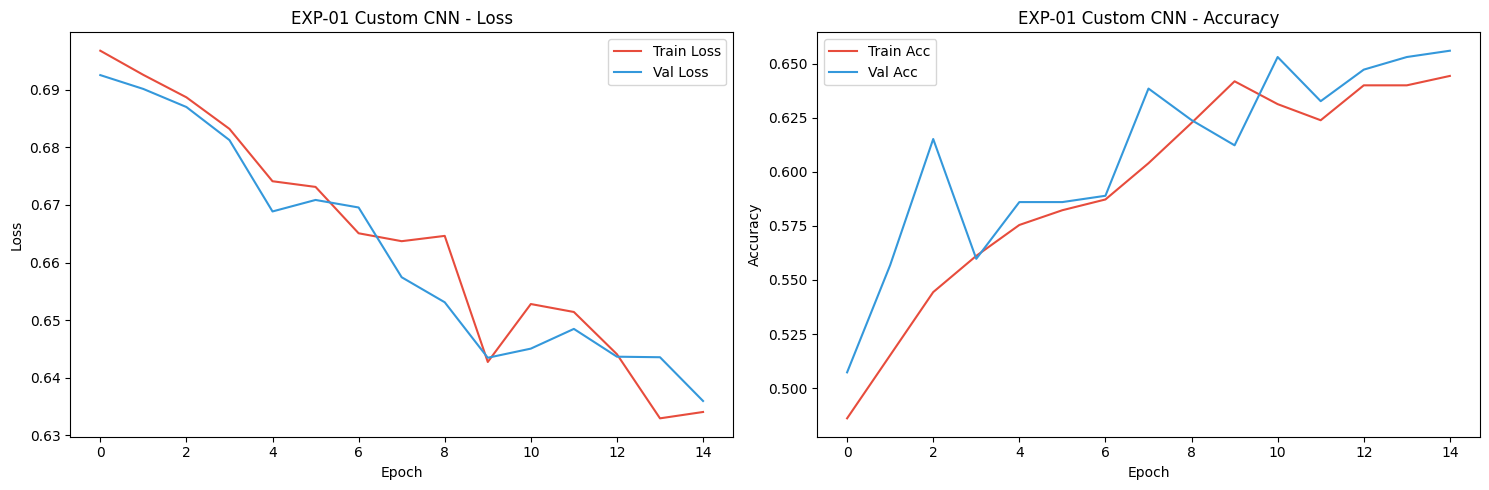


--- EXP-01 Test Set Performance ---
Accuracy: 0.7110
Precision: 0.6895
Recall: 0.7616
F1-Score: 0.7238
ROC-AUC: 0.7910

Logged EXP-01 to ..\data\processed\experiment_log.csv


In [12]:
# Cell 8: Plot Curves & Evaluate Test Set
def plot_training_curves(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    # Loss 
    axes[0].plot(history["train_loss"], label="Train Loss", color="#e74c3c")
    axes[0].plot(history["val_loss"], label="Val Loss", color="#3498db")
    axes[0].set_title(f"{title} - Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].legend()

    # Accuracy
    axes[1].plot(history["train_acc"], label="Train Acc", color="#e74c3c")
    axes[1].plot(history["val_acc"], label="Val Acc", color="#3498db")
    axes[1].set_title(f"{title} - Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy")
    axes[1].legend()
    
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"{title.replace(' ', '_').replace('(', '').replace(')', '')}_curves.png", dpi=150)
    plt.show()

plot_training_curves(history_exp01, "EXP-01 Custom CNN")

# Evaluate on Test Set
model_exp01.eval()
all_preds = []
all_labels = []
all_probs = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model_exp01(images)
        probs = torch.softmax(outputs, dim=1)[:, 1] # Probability of class 1 (damaged)
        _, predicted = torch.max(outputs, 1)
        
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())
        all_probs.extend(probs.cpu().numpy())

# Calculate metrics
acc = accuracy_score(all_labels, all_preds)
prec = precision_score(all_labels, all_preds)
rec = recall_score(all_labels, all_preds)
f1 = f1_score(all_labels, all_preds)
auc = roc_auc_score(all_labels, all_probs)

print("\n--- EXP-01 Test Set Performance ---")
print(f"Accuracy: {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall: {rec:.4f}")
print(f"F1-Score: {f1:.4f}")
print(f"ROC-AUC: {auc:.4f}")

# Log to CSV
exp_log_01 = pd.DataFrame([{
    "experiment_id": "EXP-01",
    "model_name": "Custom_CNN",
    "learning_rate": LR,
    "batch_size": BATCH_SIZE,
    "epochs": EPOCHS,
    "accuracy": acc,
    "precision": prec,
    "recall": rec,
    "f1_score": f1,
    "roc_auc": auc,
    "training_time": time_exp01,
    "inference_time": np.nan # We will measure this later
}])

log_path = PROCESSED_DIR / "experiment_log.csv"
exp_log_01.to_csv(log_path, mode='a', header=False, index=False)
print(f"\nLogged EXP-01 to {log_path}")    

In [13]:
# Cell 9: EXP-02 ResNet18 (Frozen Backbone)

# 1. Load pre-trained ResNet18
model_exp02 = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# 2. Freeze all layers (we don't want to change the pre-trained weights)
for param in model_exp02.parameters():
    param.requires_grad = False

# 3. Replace the final fully connected layer (fc) to match our 2 classes
# The original fc has 512 input features.
num_ftrs = model_exp02.fc.in_features
model_exp02.fc = nn.Linear(num_ftrs, 2)

# Move to device
model_exp02 = model_exp02.to(device)

# 4. Define hyperparameters for frozern training
EPOCHS_EXP02 = 10  # Usually converges faster
LR_EXP02 = 0.001

# Train 
model_exp02, history_exp02, time_exp02 = train_one_experiment(
    model=model_exp02,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=EPOCHS_EXP02,
    lr=LR_EXP02,
    experiment_name="EXP-02 (ResNet18 Frozen)"
)

# Save weights
torch.save(model_exp02.state_dict(), MODELS_DIR / "exp02_resnet18_frozen.pth")
print(f"Saved model to {MODELS_DIR / 'exp02_resnet18_frozen.pth'}")

🚀 Starting EXP-02 (ResNet18 Frozen) for 10 epochs...
Epoch 1/10 | Train Loss: 0.4743 Acc: 0.7846 | Val Loss: 0.5845 Acc: 0.7201
Epoch 2/10 | Train Loss: 0.3361 Acc: 0.8672 | Val Loss: 0.3274 Acc: 0.8484
Epoch 3/10 | Train Loss: 0.3327 Acc: 0.8579 | Val Loss: 0.3049 Acc: 0.8571
Epoch 4/10 | Train Loss: 0.2919 Acc: 0.8827 | Val Loss: 0.2927 Acc: 0.8630
Epoch 5/10 | Train Loss: 0.3045 Acc: 0.8783 | Val Loss: 0.2828 Acc: 0.8717
Epoch 6/10 | Train Loss: 0.2871 Acc: 0.8752 | Val Loss: 0.2946 Acc: 0.8776
Epoch 7/10 | Train Loss: 0.3030 Acc: 0.8659 | Val Loss: 0.2821 Acc: 0.8746
Epoch 8/10 | Train Loss: 0.2745 Acc: 0.8845 | Val Loss: 0.2732 Acc: 0.8776
Epoch 9/10 | Train Loss: 0.2776 Acc: 0.8802 | Val Loss: 0.2887 Acc: 0.8688
Epoch 10/10 | Train Loss: 0.2770 Acc: 0.8908 | Val Loss: 0.2830 Acc: 0.8746
✅ Finished EXP-02 (ResNet18 Frozen) in 221.6s. Best Val Loss: 0.2732
Saved model to ..\models\exp02_resnet18_frozen.pth


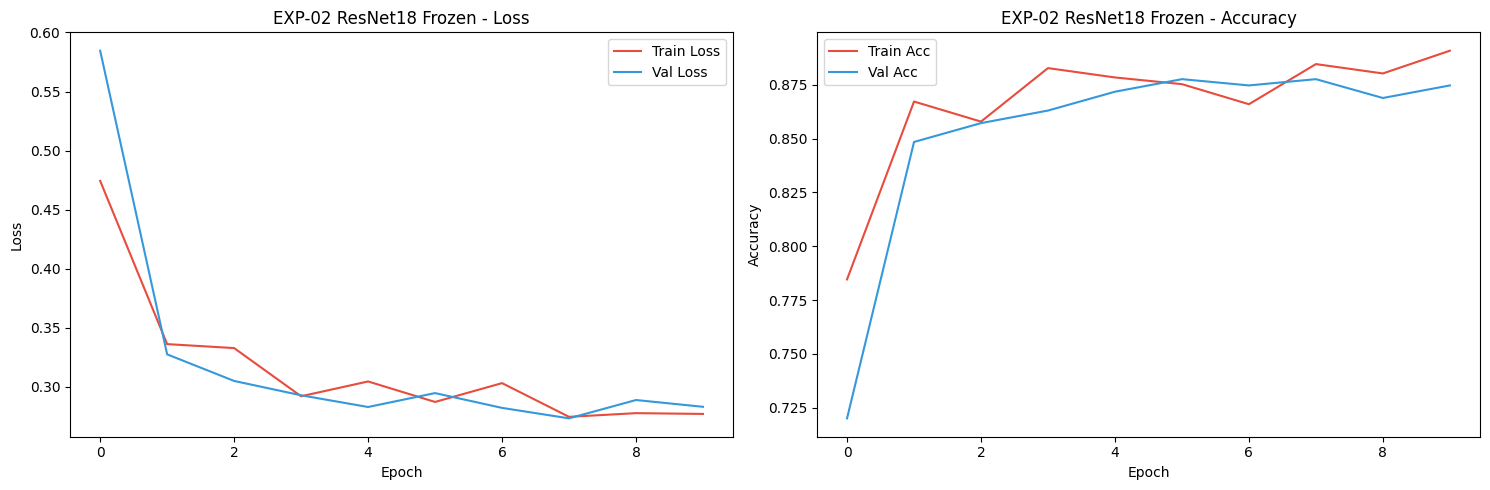


--- EXP-02 Test Set Performance ---
Accuracy: 0.9249
Precision: 0.9294
Recall: 0.9186
F1-Score: 0.9240
ROC-AUC: 0.9798

Logged EXP-02 to ..\data\processed\experiment_log.csv


In [14]:
# Cell 10: Evaluate EXP-02

plot_training_curves(history_exp02, "EXP-02 ResNet18 Frozen")

model_exp02.eval()
all_preds = []
all_labels = []
all_probs = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model_exp02(images)
        probs = torch.softmax(outputs, dim=1)[:, 1]
        _, predicted = torch.max(outputs, 1)
        
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())
        all_probs.extend(probs.cpu().numpy())

acc = accuracy_score(all_labels, all_preds)
prec = precision_score(all_labels, all_preds)
rec = recall_score(all_labels, all_preds)
f1 = f1_score(all_labels, all_preds)
auc = roc_auc_score(all_labels, all_probs)

print("\n--- EXP-02 Test Set Performance ---")
print(f"Accuracy: {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall: {rec:.4f}")
print(f"F1-Score: {f1:.4f}")
print(f"ROC-AUC: {auc:.4f}")

# Log
exp_log_02 = pd.DataFrame([{
    "experiment_id": "EXP-02",
    "model_name": "ResNet18_Frozen",
    "learning_rate": LR_EXP02,
    "batch_size": BATCH_SIZE,
    "epochs": EPOCHS_EXP02,
    "accuracy": acc,
    "precision": prec,
    "recall": rec,
    "f1_score": f1,
    "roc_auc": auc,
    "training_time": time_exp02,
    "inference_time": np.nan
}])

log_path = PROCESSED_DIR / "experiment_log.csv"
exp_log_02.to_csv(log_path, mode='a', header=False, index=False)
print(f"\nLogged EXP-02 to {log_path}")

In [15]:
# Cell 11: EXP-03 ResNet18 (Fine-Tuned)
# 1. Load the saved weights from EXP-02
model_exp03 = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
num_ftrs = model_exp03.fc.in_features
model_exp03.fc = nn.Linear(num_ftrs, 2)
model_exp03.load_state_dict(torch.load(MODELS_DIR / "exp02_resnet18_frozen.pth"))
model_exp03 = model_exp03.to(device)

# 2. Unfreeze layer4
for param in model_exp03.layer4.parameters():
    param.requires_grad = True

# 3. Define hyperparameters for fine-tuning
EPOCHS_EXP03 = 10
LR_EXP03 = 0.0001 # MUCH lower learning rate!

# 4. Train
model_exp03, history_exp03, time_exp03 = train_one_experiment(
    model=model_exp03,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=EPOCHS_EXP03,
    lr=LR_EXP03,
    experiment_name="EXP-03 (ResNet18 Fine-Tuned)"
)

# 5. Save weights
torch.save(model_exp03.state_dict(), MODELS_DIR / "exp03_resnet18_finetuned.pth")
print(f"Saved model to {MODELS_DIR / 'exp03_resnet18_finetuned.pth'}")

C:\Users\ASUS\AppData\Local\Temp\ipykernel_20960\2328292776.py:6: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model_exp03.load_state_dict(torch.load(MODELS_DIR / "exp02_re

🚀 Starting EXP-03 (ResNet18 Fine-Tuned) for 10 epochs...
Epoch 1/10 | Train Loss: 0.2595 Acc: 0.8982 | Val Loss: 0.2617 Acc: 0.9125
Epoch 2/10 | Train Loss: 0.1369 Acc: 0.9472 | Val Loss: 0.2661 Acc: 0.9096
Epoch 3/10 | Train Loss: 0.0827 Acc: 0.9702 | Val Loss: 0.3096 Acc: 0.9184
Epoch 4/10 | Train Loss: 0.0953 Acc: 0.9603 | Val Loss: 0.3023 Acc: 0.9242
Epoch 5/10 | Train Loss: 0.0648 Acc: 0.9783 | Val Loss: 0.2344 Acc: 0.9125
Epoch 6/10 | Train Loss: 0.0494 Acc: 0.9820 | Val Loss: 0.2315 Acc: 0.9388
Epoch 7/10 | Train Loss: 0.0502 Acc: 0.9808 | Val Loss: 0.2818 Acc: 0.9155
Epoch 8/10 | Train Loss: 0.0417 Acc: 0.9845 | Val Loss: 0.2204 Acc: 0.9213
Epoch 9/10 | Train Loss: 0.0416 Acc: 0.9857 | Val Loss: 0.3242 Acc: 0.9067
Epoch 10/10 | Train Loss: 0.0486 Acc: 0.9814 | Val Loss: 0.3387 Acc: 0.9067
✅ Finished EXP-03 (ResNet18 Fine-Tuned) in 225.2s. Best Val Loss: 0.2204
Saved model to ..\models\exp03_resnet18_finetuned.pth


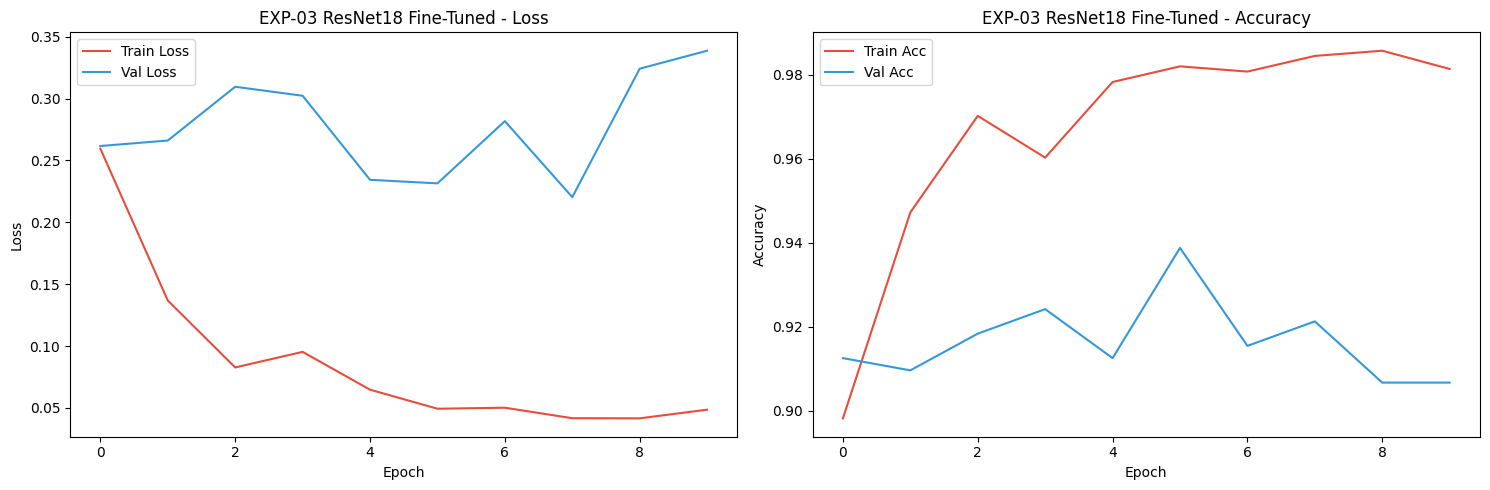


--- EXP-03 Test Set Performance ---
Accuracy: 0.9595
Precision: 0.9540
Recall: 0.9651
F1-Score: 0.9595
ROC-AUC: 0.9929

Logged EXP-03 to ..\data\processed\experiment_log.csv


In [16]:
# Cell 12: Evaluate EXP-03
plot_training_curves(history_exp03, "EXP-03 ResNet18 Fine-Tuned")

model_exp03.eval()
all_preds = []
all_labels = []
all_probs = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model_exp03(images)
        probs = torch.softmax(outputs, dim=1)[:, 1]
        _, predicted = torch.max(outputs, 1)
        
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())
        all_probs.extend(probs.cpu().numpy())

acc = accuracy_score(all_labels, all_preds)
prec = precision_score(all_labels, all_preds)
rec = recall_score(all_labels, all_preds)
f1 = f1_score(all_labels, all_preds)
auc = roc_auc_score(all_labels, all_probs)

print("\n--- EXP-03 Test Set Performance ---")
print(f"Accuracy: {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall: {rec:.4f}")
print(f"F1-Score: {f1:.4f}")
print(f"ROC-AUC: {auc:.4f}")

# Log
exp_log_03 = pd.DataFrame([{
    "experiment_id": "EXP-03",
    "model_name": "ResNet18_FineTuned",
    "learning_rate": LR_EXP03,
    "batch_size": BATCH_SIZE,
    "epochs": EPOCHS_EXP03,
    "accuracy": acc,
    "precision": prec,
    "recall": rec,
    "f1_score": f1,
    "roc_auc": auc,
    "training_time": time_exp03,
    "inference_time": np.nan
}])

log_path = PROCESSED_DIR / "experiment_log.csv"
exp_log_03.to_csv(log_path, mode='a', header=False, index=False)
print(f"\nLogged EXP-03 to {log_path}")

In [17]:
# Cell 13: EXP-04 MobileNetV3 (Fine-Tuned)

# 1. Load pre-trained MobileNetV3
model_exp04 = models.mobilenet_v3_small(weights=models.MobileNet_V3_Small_Weights.DEFAULT)

# 2. Replace the classifier head
num_ftrs = model_exp04.classifier[3].in_features
model_exp04.classifier[3] = nn.Linear(num_ftrs, 2)

# 3. Freeze the base, train the head first (optional, but helps stability)
for param in model_exp04.features.parameters():
    param.requires_grad = False
    
model_exp04 = model_exp04.to(device)

# 4. Unfreeze the last few blocks of features for fine-tuning
# MobileNet's features are a Sequential block. We'll unfreeze the last 3 blocks.
for param in list(model_exp04.features.parameters())[-6:]:
    param.requires_grad = True

EPOCHS_EXP04 = 10
LR_EXP04 = 0.0001

# 5. Train
model_exp04, history_exp04, time_exp04 = train_one_experiment(
    model=model_exp04,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=EPOCHS_EXP04,
    lr=LR_EXP04,
    experiment_name="EXP-04 (MobileNetV3 Fine-Tuned)"
)

# 6. Save weights
torch.save(model_exp04.state_dict(), MODELS_DIR / "exp04_mobilenetv3.pth")
print(f"Saved model to {MODELS_DIR / 'exp04_mobilenetv3.pth'}")

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to C:\Users\ASUS/.cache\torch\hub\checkpoints\mobilenet_v3_small-047dcff4.pth
100%|██████████| 9.83M/9.83M [00:00<00:00, 14.1MB/s]


🚀 Starting EXP-04 (MobileNetV3 Fine-Tuned) for 10 epochs...
Epoch 1/10 | Train Loss: 0.4992 Acc: 0.7790 | Val Loss: 0.8566 Acc: 0.5918
Epoch 2/10 | Train Loss: 0.3453 Acc: 0.8560 | Val Loss: 0.6662 Acc: 0.7376
Epoch 3/10 | Train Loss: 0.2928 Acc: 0.8740 | Val Loss: 0.6906 Acc: 0.7609
Epoch 4/10 | Train Loss: 0.2812 Acc: 0.8833 | Val Loss: 0.4070 Acc: 0.8542
Epoch 5/10 | Train Loss: 0.2697 Acc: 0.8833 | Val Loss: 0.4233 Acc: 0.8426
Epoch 6/10 | Train Loss: 0.2448 Acc: 0.8963 | Val Loss: 0.3983 Acc: 0.8513
Epoch 7/10 | Train Loss: 0.2313 Acc: 0.9056 | Val Loss: 0.3066 Acc: 0.8834
Epoch 8/10 | Train Loss: 0.2068 Acc: 0.9212 | Val Loss: 0.3401 Acc: 0.8717
Epoch 9/10 | Train Loss: 0.2111 Acc: 0.9162 | Val Loss: 0.3075 Acc: 0.8863
Epoch 10/10 | Train Loss: 0.2039 Acc: 0.9193 | Val Loss: 0.3276 Acc: 0.8776
✅ Finished EXP-04 (MobileNetV3 Fine-Tuned) in 206.0s. Best Val Loss: 0.3066
Saved model to ..\models\exp04_mobilenetv3.pth


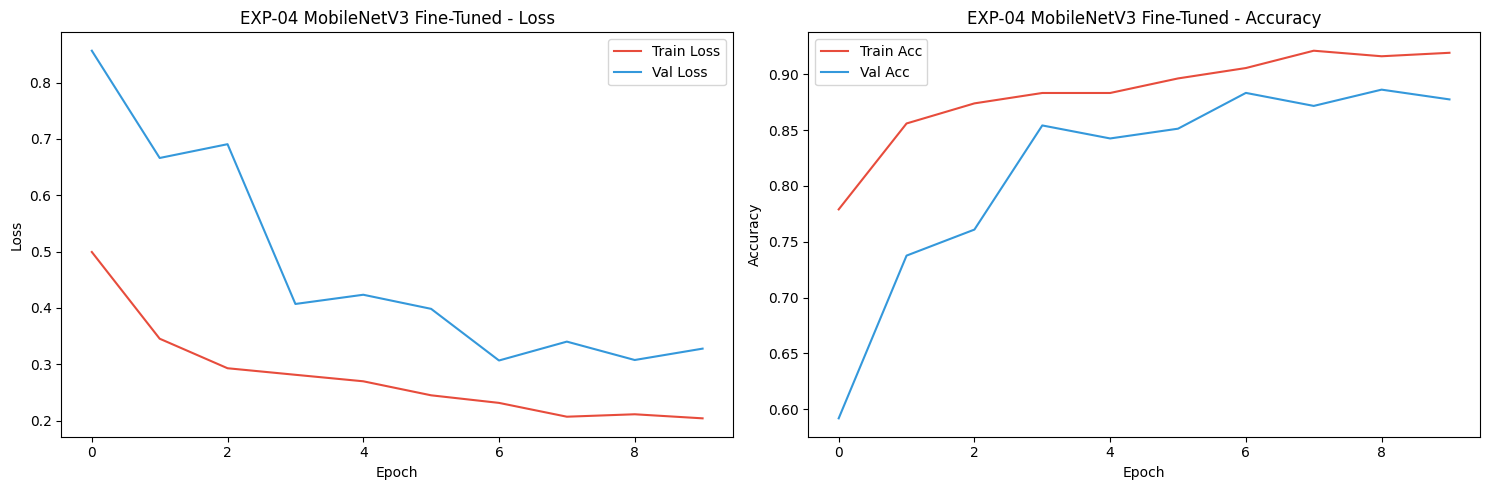


--- EXP-04 Test Set Performance ---
Accuracy: 0.9162
Precision: 0.9613
Recall: 0.8663
F1-Score: 0.9113
ROC-AUC: 0.9808

Logged EXP-04 to ..\data\processed\experiment_log.csv


In [18]:
# Cell 14: Evaluate EXP-04
plot_training_curves(history_exp04, "EXP-04 MobileNetV3 Fine-Tuned")

model_exp04.eval()
all_preds = []
all_labels = []
all_probs = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model_exp04(images)
        probs = torch.softmax(outputs, dim=1)[:, 1]
        _, predicted = torch.max(outputs, 1)
        
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())
        all_probs.extend(probs.cpu().numpy())

acc = accuracy_score(all_labels, all_preds)
prec = precision_score(all_labels, all_preds)
rec = recall_score(all_labels, all_preds)
f1 = f1_score(all_labels, all_preds)
auc = roc_auc_score(all_labels, all_probs)

print("\n--- EXP-04 Test Set Performance ---")
print(f"Accuracy: {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall: {rec:.4f}")
print(f"F1-Score: {f1:.4f}")
print(f"ROC-AUC: {auc:.4f}")

# Log
exp_log_04 = pd.DataFrame([{
    "experiment_id": "EXP-04",
    "model_name": "MobileNetV3_FineTuned",
    "learning_rate": LR_EXP04,
    "batch_size": BATCH_SIZE,
    "epochs": EPOCHS_EXP04,
    "accuracy": acc,
    "precision": prec,
    "recall": rec,
    "f1_score": f1,
    "roc_auc": auc,
    "training_time": time_exp04,
    "inference_time": np.nan
}])

log_path = PROCESSED_DIR / "experiment_log.csv"
exp_log_04.to_csv(log_path, mode='a', header=False, index=False)
print(f"\nLogged EXP-04 to {log_path}")

In [19]:
# Cell 15: EXP-05 EfficientNet-B0

# 1. Load pre-trained EfficientNet-B0
model_exp05 = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)

# 2. Replace the classifier head
num_ftrs = model_exp05.classifier[1].in_features
model_exp05.classifier[1] = nn.Linear(num_ftrs, 2)

# 3. Freeze the base
for param in model_exp05.features.parameters():
    param.requires_grad = False

# 4. Unfreeze the last few blocks for fine-tuning
for param in list(model_exp05.features.parameters())[-6:]:
    param.requires_grad = True

model_exp05 = model_exp05.to(device)

EPOCHS_EXP05 = 10
LR_EXP05 = 0.0001

# 5. Train
model_exp05, history_exp05, time_exp05 = train_one_experiment(
    model=model_exp05,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=EPOCHS_EXP05,
    lr=LR_EXP05,
    experiment_name="EXP-05 (EfficientNet-B0)"
)

# 6. Save weights
torch.save(model_exp05.state_dict(), MODELS_DIR / "exp05_efficientnet_b0.pth")
print(f"Saved model to {MODELS_DIR / 'exp05_efficientnet_b0.pth'}")

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to C:\Users\ASUS/.cache\torch\hub\checkpoints\efficientnet_b0_rwightman-7f5810bc.pth
100%|██████████| 20.5M/20.5M [00:01<00:00, 11.4MB/s]


🚀 Starting EXP-05 (EfficientNet-B0) for 10 epochs...
Epoch 1/10 | Train Loss: 0.4970 Acc: 0.8007 | Val Loss: 0.3809 Acc: 0.8426
Epoch 2/10 | Train Loss: 0.3337 Acc: 0.8672 | Val Loss: 0.3224 Acc: 0.8630
Epoch 3/10 | Train Loss: 0.2876 Acc: 0.8821 | Val Loss: 0.3032 Acc: 0.8659
Epoch 4/10 | Train Loss: 0.2606 Acc: 0.8945 | Val Loss: 0.2764 Acc: 0.8863
Epoch 5/10 | Train Loss: 0.2326 Acc: 0.9106 | Val Loss: 0.2633 Acc: 0.8805
Epoch 6/10 | Train Loss: 0.2090 Acc: 0.9218 | Val Loss: 0.2621 Acc: 0.8805
Epoch 7/10 | Train Loss: 0.2130 Acc: 0.9162 | Val Loss: 0.2428 Acc: 0.8834
Epoch 8/10 | Train Loss: 0.2024 Acc: 0.9156 | Val Loss: 0.2512 Acc: 0.8834
Epoch 9/10 | Train Loss: 0.1964 Acc: 0.9261 | Val Loss: 0.2376 Acc: 0.8863
Epoch 10/10 | Train Loss: 0.1855 Acc: 0.9311 | Val Loss: 0.2440 Acc: 0.8863
✅ Finished EXP-05 (EfficientNet-B0) in 194.0s. Best Val Loss: 0.2376
Saved model to ..\models\exp05_efficientnet_b0.pth


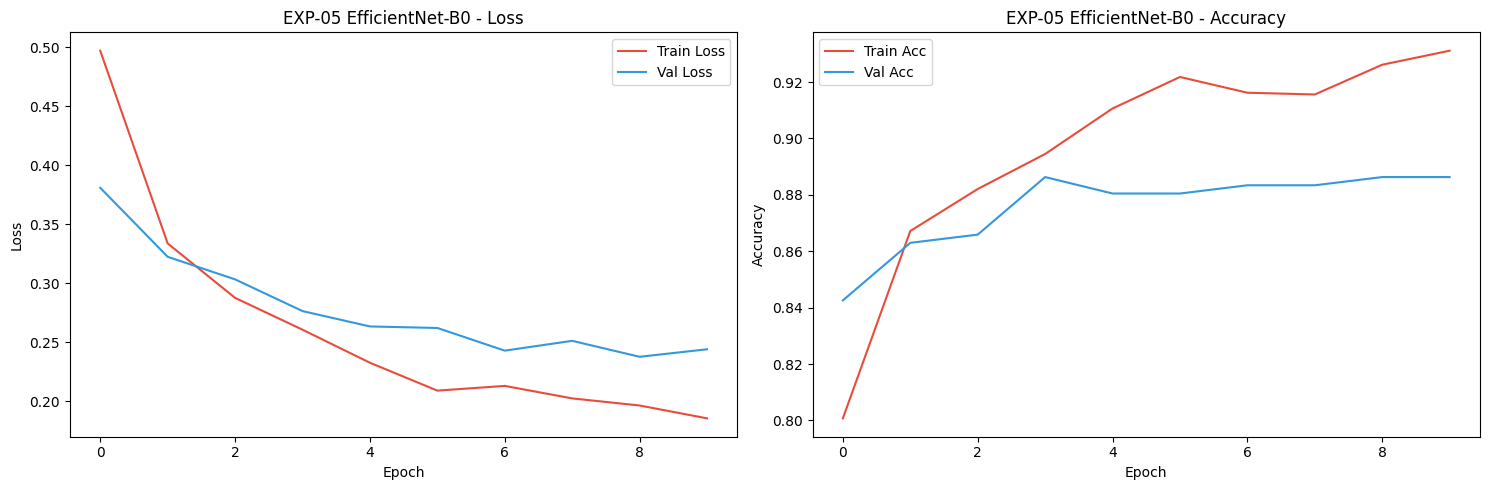


--- EXP-05 Test Set Performance ---
Accuracy: 0.9335
Precision: 0.9627
Recall: 0.9012
F1-Score: 0.9309
ROC-AUC: 0.9894

Logged EXP-05 to ..\data\processed\experiment_log.csv


In [20]:
# Cell 16: Evaluate EXP-05
plot_training_curves(history_exp05, "EXP-05 EfficientNet-B0")

model_exp05.eval()
all_preds = []
all_labels = []
all_probs = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model_exp05(images)
        probs = torch.softmax(outputs, dim=1)[:, 1]
        _, predicted = torch.max(outputs, 1)
        
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())
        all_probs.extend(probs.cpu().numpy())

acc = accuracy_score(all_labels, all_preds)
prec = precision_score(all_labels, all_preds)
rec = recall_score(all_labels, all_preds)
f1 = f1_score(all_labels, all_preds)
auc = roc_auc_score(all_labels, all_probs)

print("\n--- EXP-05 Test Set Performance ---")
print(f"Accuracy: {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall: {rec:.4f}")
print(f"F1-Score: {f1:.4f}")
print(f"ROC-AUC: {auc:.4f}")

# Log
exp_log_05 = pd.DataFrame([{
    "experiment_id": "EXP-05",
    "model_name": "EfficientNet_B0",
    "learning_rate": LR_EXP05,
    "batch_size": BATCH_SIZE,
    "epochs": EPOCHS_EXP05,
    "accuracy": acc,
    "precision": prec,
    "recall": rec,
    "f1_score": f1,
    "roc_auc": auc,
    "training_time": time_exp05,
    "inference_time": np.nan
}])

log_path = PROCESSED_DIR / "experiment_log.csv"
exp_log_05.to_csv(log_path, mode='a', header=False, index=False)
print(f"\nLogged EXP-05 to {log_path}")

In [21]:
# Cell 17: Fix File Locations
import shutil

# 1. Create new directories
EXPERIMENTS_DIR = Path("../reports/experiments")
EXPERIMENTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_CLASS_DIR = Path("../models/classification")
MODELS_CLASS_DIR.mkdir(parents=True, exist_ok=True)

# 2. Move log
shutil.copy(PROCESSED_DIR / "experiment_log.csv", EXPERIMENTS_DIR / "experiment_log.csv")
print(f"Log copied to {EXPERIMENTS_DIR / 'experiment_log.csv'}")

# 3. Move models
for model_file in MODELS_DIR.glob("*.pth"):
    shutil.move(str(model_file), str(MODELS_CLASS_DIR / model_file.name))
print(f"Models moved to {MODELS_CLASS_DIR}")

Log copied to ..\reports\experiments\experiment_log.csv
Models moved to ..\models\classification
